# Notebook 2 : estimation de la volatilité sur le Brent

Une banque qui vend une option sur le Brent le 1er janvier doit choisir un σ pour la pricer et la couvrir. Elle ne connaît pas la vol de l'année qui commence, elle doit l'estimer avec le passé.

Ce notebook ne traite que l'estimation : pour chaque estimateur, on compare le σ estimé à ce qui s'est passé ensuite. Plus tard, on fera la même chose pour la corrélation ρ du spread. La méthode de couverture est testée dans le notebook 1, et le trade réel qui combine les deux sera dans le notebook 3.

| Partie | Estimateur | État |
|---|---|---|
| 1 | Vol historique de l'année précédente | faite |
| 2 | EWMA (plus de poids aux jours récents) | faite |
| 3 | Comparaison des estimateurs | à venir |

## 0. Données

Prix de clôture quotidiens du Brent (`BZ=F`) de 2012 à 2024, avec `get_prices`. On commence en 2012 pour pouvoir estimer σ dès le 1er janvier 2013 à partir de l'année 2012.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from spread_options.data import get_prices
from spread_options.volatility import historical_vol, ewma_vol

prices = get_prices("BZ=F", "01/01/2012", "31/12/2024")
print(f"{len(prices)} prix, du {prices.index[0].date()} au {prices.index[-1].date()}")

3251 prix, du 2012-01-03 au 2024-12-31


## 1. Vol historique : estimé contre réalisé

Pour chaque année $y$ de 2013 à 2024 :

$$\sigma^{\text{est}}_y = \text{vol de l'année } y-1 \quad(\text{connue le 1er janvier}) \qquad \sigma^{\text{réal}}_y = \text{vol de l'année } y \quad(\text{connue le 31 décembre})$$

$$\text{erreur}_y = \sigma^{\text{est}}_y - \sigma^{\text{réal}}_y$$

Une erreur positive veut dire qu'on a surestimé la vol, une erreur négative qu'on l'a sous-estimée.

On résume les douze erreurs de deux façons. Dans l'erreur moyenne, les erreurs positives et négatives se compensent : elle dit si l'on se trompe toujours dans le même sens (un biais). Dans l'erreur absolue moyenne, on enlève les signes avant de faire la moyenne : elle dit de combien on se trompe en général.

In [2]:
years = list(range(2013, 2025)) # 2013, ..., 2024 (range excludes 2025)
sigma_est = [] # what the bank knows on January 1st
sigma_real = [] # what really happened during the year
for year in years:
    # prices["2012"] (text) = every date of 2012; prices[2012] (number) would be the 2013th price
    sigma_est.append(historical_vol(prices[str(year - 1)])) # vol of the PREVIOUS year
    sigma_real.append(historical_vol(prices[str(year)])) # vol of THIS year, known only at the end
sigma_est = np.array(sigma_est) # lists -> arrays, to subtract them element by element
sigma_real = np.array(sigma_real)
errors = sigma_est - sigma_real # > 0: overestimated, < 0: underestimated

for year, est, real, err in zip(years, sigma_est, sigma_real, errors): # walk the 4 lists together
    print(f"{year} | estimé {est:.1%} | réalisé {real:.1%} | erreur {err * 100:+.1f} pts")
print() # empty line
print(f"erreur moyenne {errors.mean() * 100:+.1f} pts | erreur absolue moyenne {np.abs(errors).mean() * 100:.1f} pts")

2013 | estimé 23.2% | réalisé 16.8% | erreur +6.5 pts
2014 | estimé 16.8% | réalisé 20.7% | erreur -3.9 pts
2015 | estimé 20.7% | réalisé 44.1% | erreur -23.5 pts
2016 | estimé 44.1% | réalisé 45.0% | erreur -0.9 pts
2017 | estimé 45.0% | réalisé 24.0% | erreur +21.1 pts
2018 | estimé 24.0% | réalisé 30.6% | erreur -6.7 pts
2019 | estimé 30.6% | réalisé 31.4% | erreur -0.7 pts
2020 | estimé 31.4% | réalisé 71.4% | erreur -40.0 pts
2021 | estimé 71.4% | réalisé 32.5% | erreur +38.9 pts
2022 | estimé 32.5% | réalisé 46.6% | erreur -14.1 pts
2023 | estimé 46.6% | réalisé 31.7% | erreur +14.9 pts
2024 | estimé 31.7% | réalisé 26.5% | erreur +5.2 pts

erreur moyenne -0.3 pts | erreur absolue moyenne 14.7 pts


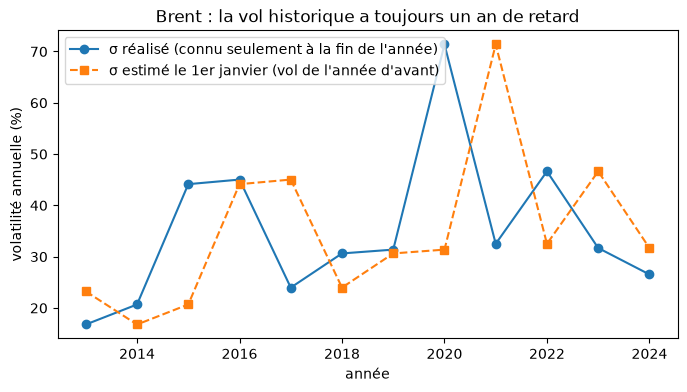

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(years, sigma_real * 100, "o-", label="σ réalisé (connu seulement à la fin de l'année)") # o- = dots + line
ax.plot(years, sigma_est * 100, "s--", label="σ estimé le 1er janvier (vol de l'année d'avant)") # s-- = squares + dashes
ax.set_xlabel("année")
ax.set_ylabel("volatilité annuelle (%)")
ax.set_title("Brent : la vol historique a toujours un an de retard")
ax.legend()
plt.show()

### Lecture

La courbe estimée est la courbe réalisée décalée d'un an. Le pic du Covid (71 % en 2020) n'entre dans l'estimation qu'en 2021, l'année où le marché s'est calmé.

L'estimateur rate donc les hausses de vol (2015, 2020, 2022), années où la banque vend l'option trop bas et perd, et il surréagit l'année suivante (2017, 2021, 2023), où elle la vend trop cher.

L'erreur moyenne est proche de 0, donc l'estimateur n'a pas de biais. L'erreur typique est pourtant d'environ 15 points. Si la vol était constante, une année de données la donnerait à 0,9 point près (c'est ce que mesure `test_volatility.py` sur un GBM simulé à 20 %). Le manque de données n'explique donc pas l'erreur : la vol du Brent change d'une année à l'autre.

La partie 2 testera un estimateur qui réagit plus vite aux derniers jours, l'EWMA.

## 2. EWMA : estimé contre réalisé

La vol historique donne le même poids aux 252 jours de l'année. L'EWMA met à jour son estimation chaque soir :

$$\sigma^2_t = \lambda\,\sigma^2_{t-1} + (1-\lambda)\,r_t^2, \qquad \lambda = 0{,}94$$

En français : la nouvelle variance garde 94 % de celle de la veille et prend 6 % du rendement du jour au carré. Un rendement vieux de $k$ jours pèse donc $0{,}06 \times 0{,}94^k$ : 6 % le jour même, 3 % au bout de 11 jours, presque rien après trois mois. L'EWMA au 31 décembre mesure surtout la vol des dernières semaines.

On garde la même grille que dans la partie 1. Seule l'estimation change :

$$\sigma^{\text{est}}_y = \text{EWMA au 31 décembre de l'année } y-1 \qquad \sigma^{\text{réal}}_y = \text{vol de l'année } y \ (\text{inchangée})$$

`ewma_vol` démarre avec le premier rendement de l'année $y-1$ au carré. Ce point de départ a environ 250 jours d'ancienneté au 31 décembre, son poids vaut $0{,}94^{250} \approx 2 \times 10^{-7}$, donc il ne change pas le résultat.

In [4]:
sigma_ewma = [] # EWMA at December 31st of the previous year
for year in years:
    sigma_ewma.append(ewma_vol(prices[str(year - 1)])) # only the prices of year-1: known on January 1st
sigma_ewma = np.array(sigma_ewma)
errors_ewma = sigma_ewma - sigma_real # same realized vol as in part 1

for year, est, real, err in zip(years, sigma_ewma, sigma_real, errors_ewma):
    print(f"{year} | estimé {est:.1%} | réalisé {real:.1%} | erreur {err * 100:+.1f} pts")
print()
print(f"erreur moyenne {errors_ewma.mean() * 100:+.1f} pts | erreur absolue moyenne {np.abs(errors_ewma).mean() * 100:.1f} pts")

# same summary without 2020 (Covid): True for every year except 2020
not_2020 = np.array(years) != 2020
print(f"sans 2020 : erreur moyenne {errors_ewma[not_2020].mean() * 100:+.1f} pts"
      f" | erreur absolue moyenne {np.abs(errors_ewma[not_2020]).mean() * 100:.1f} pts"
      f" (vol historique : {np.abs(errors[not_2020]).mean() * 100:.1f} pts)")

2013 | estimé 18.0% | réalisé 16.8% | erreur +1.2 pts
2014 | estimé 14.4% | réalisé 20.7% | erreur -6.3 pts
2015 | estimé 37.1% | réalisé 44.1% | erreur -7.0 pts
2016 | estimé 39.6% | réalisé 45.0% | erreur -5.5 pts
2017 | estimé 35.2% | réalisé 24.0% | erreur +11.2 pts
2018 | estimé 20.4% | réalisé 30.6% | erreur -10.3 pts
2019 | estimé 56.5% | réalisé 31.4% | erreur +25.1 pts
2020 | estimé 24.1% | réalisé 71.4% | erreur -47.3 pts
2021 | estimé 26.4% | réalisé 32.5% | erreur -6.1 pts
2022 | estimé 37.4% | réalisé 46.6% | erreur -9.2 pts
2023 | estimé 37.2% | réalisé 31.7% | erreur +5.5 pts
2024 | estimé 32.0% | réalisé 26.5% | erreur +5.5 pts

erreur moyenne -3.6 pts | erreur absolue moyenne 11.7 pts
sans 2020 : erreur moyenne +0.4 pts | erreur absolue moyenne 8.4 pts (vol historique : 12.4 pts)


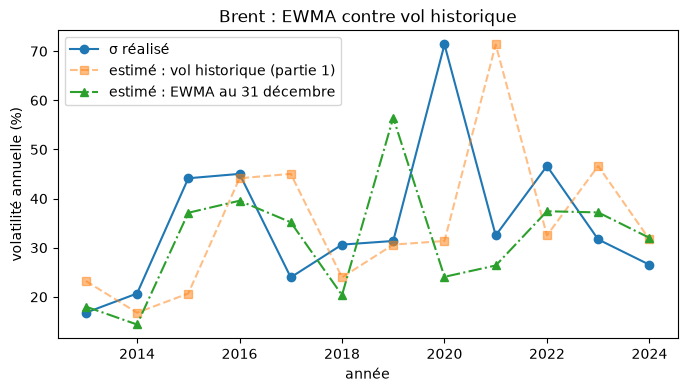

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(years, sigma_real * 100, "o-", label="σ réalisé")
ax.plot(years, sigma_est * 100, "s--", alpha=0.5, label="estimé : vol historique (partie 1)") # alpha: lighter
ax.plot(years, sigma_ewma * 100, "^-.", label="estimé : EWMA au 31 décembre") # ^-. = triangles + dash-dots
ax.set_xlabel("année")
ax.set_ylabel("volatilité annuelle (%)")
ax.set_title("Brent : EWMA contre vol historique")
ax.legend()
plt.show()

### Lecture

L'EWMA ne traîne plus le pic du Covid : fin 2020, le marché s'est calmé et l'EWMA donne 26 % pour 2021 (réalisé 32,5 %), là où la vol historique donnait 71 %. L'erreur absolue moyenne passe de 14,7 à 11,7 points.

L'EWMA a son propre défaut : il prédit une année entière avec les dernières semaines. Fin 2018, le Brent a chuté de 40 % en trois mois. L'EWMA annonce alors 56 % pour 2019, qui sera une année calme (31 %).

L'erreur moyenne de −3,6 points vient presque entièrement de 2020 (−47 points) : fin 2019, rien dans les prix n'annonçait le Covid. Sans 2020, l'EWMA n'a plus de biais et se trompe d'environ 8,4 points en moyenne, contre 12,4 pour la vol historique.

Le choix λ = 0,94 vient de RiskMetrics, qui l'a calibré pour prévoir la vol du lendemain. Pour une option à un an, un λ plus proche de 1 (mémoire plus longue) serait peut-être meilleur. La partie 3 comparera les estimateurs.